# TP2 - Informe técnico

Este informe presenta el desarrollo de un pipeline de *Computer Vision* para el reconocimiento y clasificación de razas de perros. El trabajo evoluciona desde un sistema de búsqueda por similitud basado en *embeddings* hasta un modelo de clasificación supervisada integrado con detección de objetos, permitiendo identificar múltiples perros en una misma imagen. Además, se comparan distintas arquitecturas y enfoques, evaluando su precisión, capacidad de generalización y robustez frente a imágenes fuera de distribución.

#### El informe está organizado en las siguientes secciones:

1. [Datasets](#1-datasets): presenta el dataset *70 Dog Breeds* y el conjunto propio *Out-of-Distribution* (OOD), junto con la definición de splits y el análisis de la distribución de clases.

2. [Preprocesamiento](#2-preprocesamiento): detalla las técnicas aplicadas para la obtención de embeddings y para el entrenamiento de los clasificadores.

3. [Explicación completa del pipeline](#3-explicacion-completa-del-pipeline): describe el funcionamiento de cada etapa del sistema, desde la búsqueda por similitud hasta la detección y clasificación conjunta.

4. [Justificación de los modelos elegidos](#4-justificacion-de-los-modelos-elegidos): fundamenta la elección de ConvNeXt-Tiny para embeddings, ResNet18 para clasificación y YOLOv8n para detección, comparándolos en métricas y complejidad.

5. [Proceso de entrenamiento e hiperparámetros](#5-proceso-de-entrenamiento-e-hiperparametros): documenta la configuración y los hiperparámetros utilizados en el entrenamiento de cada modelo.

6. [Resultados obtenidos](#6-resultados-obtenidos): presenta las métricas finales de cada etapa, incluyendo la visualización de embeddings mediante t-SNE y las matrices de confusión.

7. [Comparación entre enfoques](#7-comparacion-entre-enfoques): contrasta la búsqueda por similitud frente a la clasificación supervisada, y ResNet18 fine-tuned frente a la CNN personalizada.

8. [Problemas encontrados y soluciones implementadas](#8-problemas-encontrados-y-soluciones-implementadas): repasa las principales dificultades encontradas durante el desarrollo y cómo se resolvieron.

## Equipo
- Alumno 1 : Nicolás Mancini
- Alumno 2 : Juana Chies Doumecq

## 1. Datasets

Para el desarrollo y evaluación del sistema se utilizaron dos conjuntos de datos con objetivos complementarios. Por un lado, se empleó el dataset 70-Dogs, utilizado para el entrenamiento y la evaluación de la capacidad del modelo para reconocer las razas incluidas en el problema de clasificación. Por otro lado, se construyó un conjunto Out-of-Distribution (OOD) compuesto por imágenes que representan distintos escenarios no necesariamente presentes durante el entrenamiento, tales como razas desconocidas, múltiples perros en una misma escena e imágenes sin perros. La combinación de ambos datasets permite evaluar tanto el rendimiento del sistema sobre datos conocidos como su robustez y capacidad de generalización frente a entradas más desafiantes y realistas.

### Dataset 70 Dog Breeds

Este dataset es el conjunto de datos utilizado para el entrenamiento y evaluación de los modelos, compuesto por imágenes de perros pertenecientes a 70 razas diferentes. Nos proporciona una amplia diversidad de apariencias, tamaños, colores sobre los que vamos a entrenar los clasificadores para distinguir entre las distintas categorías de razas y evaluar su capacidad de generalización sobre ejemplos pertenecientes a la distribución conocida. 

#### Muestra de ejemplos 

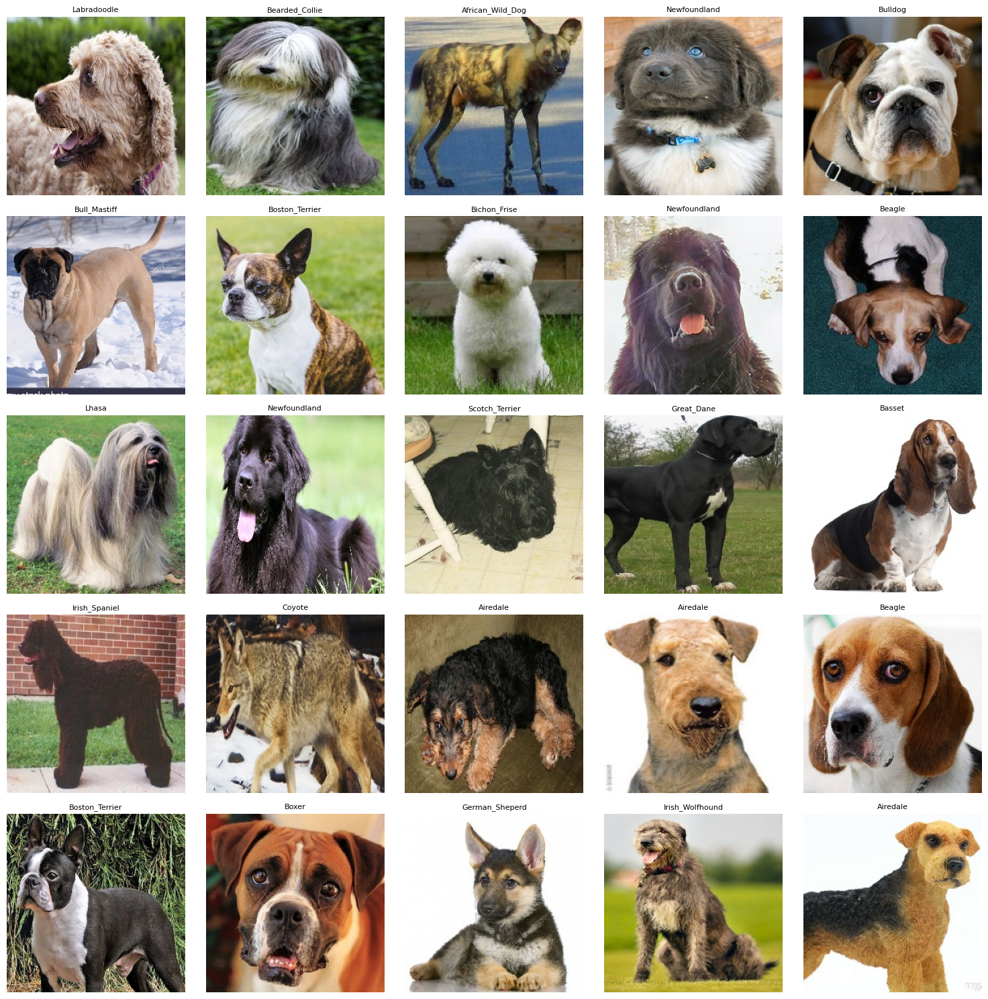

### Definición de splits

In [ ]:
Clase                   Train   Val  Test
  ──────────────────────────────────────────
  Afghan                    105    10    10
  African_Wild_Dog          109    10    10
  Airedale                  117    10    10
  American_Hairless          65    10    10
  American_Spaniel           89    10    10
  Basenji                    99    10    10
  Basset                    159    10    10
  Beagle                    123    10    10
  Bearded_Collie             79    10    10
  Bermaise                  131    10    10
  Bichon_Frise              105    10    10
  Blenheim                  113    10    10
  Bloodhound                147    10    10
  Bluetick                  107    10    10
  Border_Collie             112    10    10
  Borzoi                    110    10    10
  Boston_Terrier             79    10    10
  Boxer                     134    10    10
  Bull_Mastiff              128    10    10
  Bull_Terrier              101    10    10
  Bulldog                   125    10    10
  Cairn                     111    10    10
  Chihuahua                 108    10    10
  Chinese_Crested           118    10    10
  Chow                      110    10    10
  Clumber                   121    10    10
  Cockapoo                  129    10    10
  Cocker                    130    10    10
  Collie                    114    10    10
  Corgi                     113    10    10
  Coyote                     83    10    10
  Dalmation                  88    10    10
  Dhole                     122    10    10
  Dingo                     129    10    10
  Doberman                  120    10    10
  Elk_Hound                 100    10    10
  French_Bulldog             93    10    10
  German_Sheperd            109    10    10
  Golden_Retriever          127    10    10
  Great_Dane                123    10    10
  Great_Perenees             83    10    10
  Greyhound                 109    10    10
  Groenendael               119    10    10
  Irish_Spaniel             119    10    10
  Irish_Wolfhound            92    10    10
  Japanese_Spaniel          124    10    10
  Komondor                  105    10    10
  Labradoodle               109    10    10
  Labrador                  161    10    10
  Lhasa                     187    10    10
  Malinois                  108    10    10
  Maltese                   129    10    10
  Mex_Hairless               99    10    10
  Newfoundland               78    10    10
  Pekinese                  103    10    10
  Pit_Bull                  130    10    10
  Pomeranian                149    10    10
  Poodle                    117    10    10
  Pug                       148    10    10
  Rhodesian                 125    10    10
  Rottweiler                 98    10    10
  Saint_Bernard              78    10    10
  Schnauzer                 116    10    10
  Scotch_Terrier            150    10    10
  Shar_Pei                   91    10    10
  Shiba_Inu                  98    10    10
  Shih-Tzu                  198    10    10
  Siberian_Husky             79    10    10
  Vizsla                     81    10    10
  Yorkie                     78    10    10
  ──────────────────────────────────────────
  TOTAL                    7946   700   700

  Total: 9,346 imágenes  |  Clases: 70

El análisis de la distribución del dataset muestra un comportamiento diferenciado entre los distintos splits. Tanto el conjunto de validación como el de test presentan una distribución completamente balanceada, donde cada una de las 70 razas cuenta con exactamente 10 imágenes. Esto es altamente beneficioso para la evaluación del modelo, ya que garantiza que todas las clases contribuyan de manera equitativa a las métricas, evitando sesgos derivados de desbalances en la distribución.

En contraste, el conjunto de entrenamiento presenta un claro desbalance de clases, con una variación significativa en la cantidad de imágenes por raza. Algunas clases como *Shih-Tzu*, *Labrador*, *Basset*, *Pug* y *Pomeranian* cuentan con muchas más muestras en comparación con otras como *American_Hairless*, *Newfoundland* o *Siberian_Husky*. Este desbalance puede influir directamente en el aprendizaje del modelo, favoreciendo el desempeño en las clases mayoritarias y perjudicando a las minoritarias. Por este motivo, durante el entrenamiento se consideran estrategias de mitigación como el uso de pesos de clase en la función de pérdida, técnicas de data augmentation y posibles enfoques de re-muestreo.


#### Distribución de clases por split

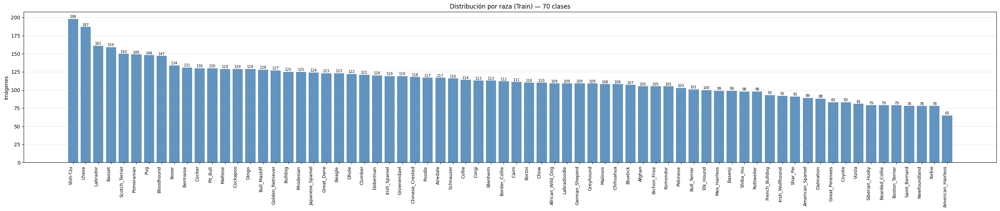

El gráfico evidencia de manera clara el **desbalance de clases** presente en el conjunto de entrenamiento. Se observa una distribución heterogénea en la cantidad de imágenes por raza, donde ciertas clases como *Shih-Tzu* concentran una proporción significativamente mayor de muestras en comparación con otras como *American_Hairless*, *Newfoundland*, *Yorkie* o *Saint_Bernard*, entre otras.

Este tipo de distribución desigual es un problema frecuente en datasets de imágenes y puede influir directamente en el proceso de aprendizaje del modelo, favoreciendo el desempeño en las clases mayoritarias y reduciendo la capacidad de generalización sobre las clases minoritarias. Por este motivo, resulta fundamental considerar este factor durante el diseño del entrenamiento e incorporar estrategias de mitigación que permitan compensar el desbalance y mejorar el rendimiento global del sistema.

### Dataset Out-of-Distribution (OOD)

Además de evaluar el rendimiento del sistema sobre datos similares a los utilizados durante el entrenamiento, resulta fundamental analizar su comportamiento frente a escenarios fuera de distribución (Out-of-Distribution, OOD). Para ello, se construyó un conjunto de imágenes que incluye perros de razas conocidas y desconocidas, escenas con múltiples perros y casos donde no hay perros presentes. 

En conjunto, estas categorías permiten construir un conjunto de evaluación OOD diverso que contempla distintos escenarios donde el sistema puede enfrentarse a entradas diferentes a las observadas durante el entrenamiento. El objetivo no es analizar cada caso de manera aislada, sino utilizar todas las imágenes OOD para medir la robustez general del pipeline y optimizar mecanismos de rechazo de consultas fuera de distribución. En particular, este conjunto será utilizado para estudiar la distribución de similitudes y determinar un umbral (threshold) que permita distinguir de forma efectiva entre consultas válidas y consultas OOD, buscando un equilibrio adecuado entre cobertura y precisión.

### Casos impementados en el dataset OOD:

#### Caso 1: Razas Conocidas (unknown_breeds)

Esta subcarpeta contiene imágenes de perros cuyas razas forman parte del conjunto de entrenamiento del clasificador. Estos ejemplos permiten verificar que el sistema mantiene un buen desempeño sobre casos conocidos incluso cuando las imágenes provienen de una distribución diferente a la utilizada para entrenar.

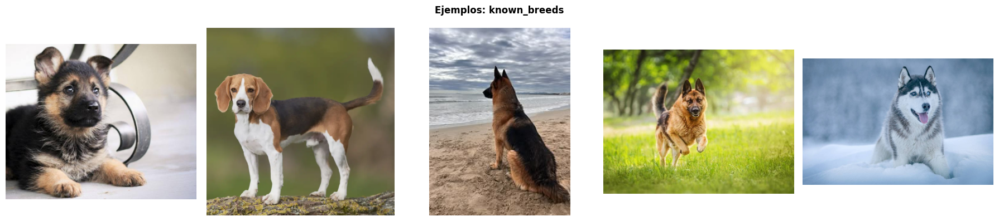

#### Caso 2: Razas Desconocidas (unknown_breeds) 

Esta subcarpeta incluye imágenes de perros pertenecientes a razas que no fueron vistas durante el entrenamiento. Este conjunto es relevante para evaluar la capacidad del sistema de reconocer sus limitaciones y evitar clasificaciones erróneas sobre categorías desconocidas.

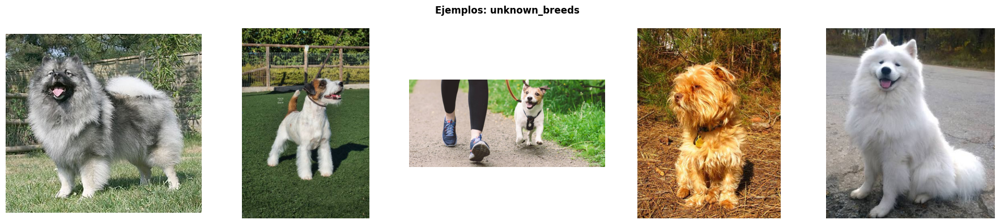

#### Caso 3: Múltiples Perros (multiple_dogs)

Esta subcarpeta contiene imágenes donde aparecen dos o más perros en una misma escena. Estos casos permiten analizar el comportamiento del pipeline en escenarios más complejos y cercanos a situaciones reales, donde múltiples objetos de interés pueden coexistir en una imagen.

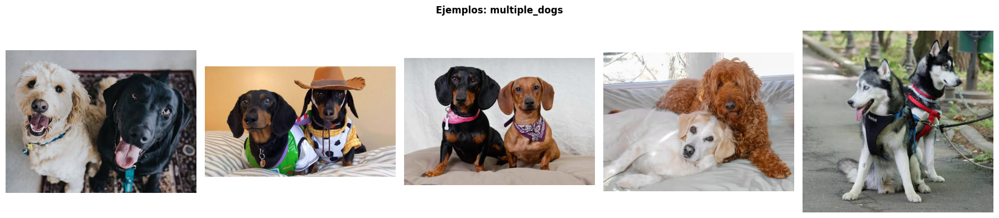

#### Caso 4: Ausencia de Perros (non_dogs)

Esta subcarpeta está compuesta por imágenes que no contienen perros, incluyendo de otros animales. Este conjunto resulta esencial para medir la tasa de falsos positivos y verificar que el sistema no identifica perros donde no los hay.

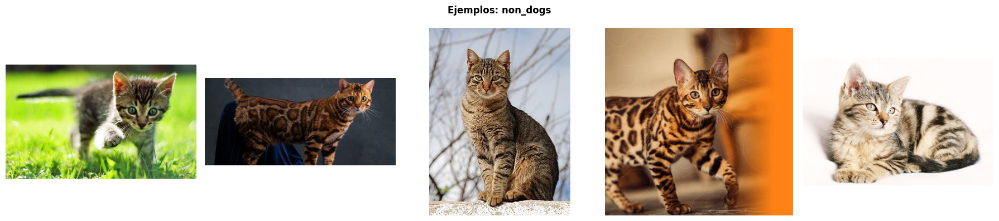

### Resoluciones originales

Las particiones de entrenamiento, validación y prueba del dataset 70-Dogs presentan una resolución uniforme de 224 × 224 píxeles, coincidiendo con el tamaño de entrada requerido por los modelos utilizados. Esta homogeneidad simplifica el procesamiento de las imágenes y garantiza consistencia entre las distintas etapas de aprendizaje y evaluación.

Por el contrario, el conjunto OOD es completamente opuesto ya que tenemos 72 resoluciones diferentes entre sus imágenes. Esta diversidad resulta valiosa para evaluar la robustez del sistema frente a datos más cercanos a escenarios reales, donde las imágenes pueden provenir de distintas fuentes y dispositivos. En este contexto, cobra especial relevancia la etapa de preprocesamiento, descrita en la sección siguiente.

## 2. Preprocesamiento

Antes de ser utilizadas por los modelos, las imágenes atraviesan una serie de etapas de preprocesamiento destinadas a garantizar la consistencia de las entradas y mejorar la capacidad de generalización durante el entrenamiento. Estas transformaciones incluyen la adaptación del tamaño de las imágenes, la normalización de los valores de los píxeles y la aplicación de técnicas específicas para mitigar el desbalance de clases y aumentar la diversidad de los datos de entrenamiento.

### Obtención de los embeddings (Etapas 1 y Etapa 2)

In [ ]:
self.transform = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

#### 1. Resize

Todas las imágenes son redimensionadas a 224 × 224 píxeles, independientemente de su resolución original. Esta transformación permite que las entradas tengan un tamaño uniforme y compatible con la arquitectura utilizada para la extracción de características y la clasificación. Además, resulta especialmente importante para el conjunto OOD, cuyas imágenes presentan una amplia variedad de resoluciones, garantizando que todas puedan ser procesadas de manera consistente por el modelo.

#### 2. Normalización

Luego del redimensionamiento, las imágenes son convertidas a tensores y normalizadas utilizando las medias y desviaciones estándar del conjunto ImageNet. Este procedimiento centra y escala los valores de los píxeles, reduciendo diferencias de iluminación y contraste entre imágenes. La normalización también favorece una convergencia más estable durante el entrenamiento y asegura compatibilidad con modelos preentrenados sobre ImageNet.

### Entrenamiento de los modelos (etapa 2)

#### 1. Correción del desbalance 

In [ ]:
y_train_labels = train_dataset.targets 
class_weights_np = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_labels), y=y_train_labels)
class_weights_tensor = torch.tensor(class_weights_np, dtype=torch.float).to(device)
        

El dataset presenta una distribución no uniforme de imágenes por raza, lo que puede inducir un sesgo del modelo hacia las clases más representadas. Para mitigar este problema, se aplicaron estrategias de corrección del desbalance que buscan otorgar una importancia más equilibrada a todas las clases durante el entrenamiento. Esto contribuye a mejorar el rendimiento sobre razas con menor cantidad de ejemplos y evita que el modelo favorezca sistemáticamente a las categorías mayoritarias.

#### 2. Data augmentation

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((self.image_size, self.image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

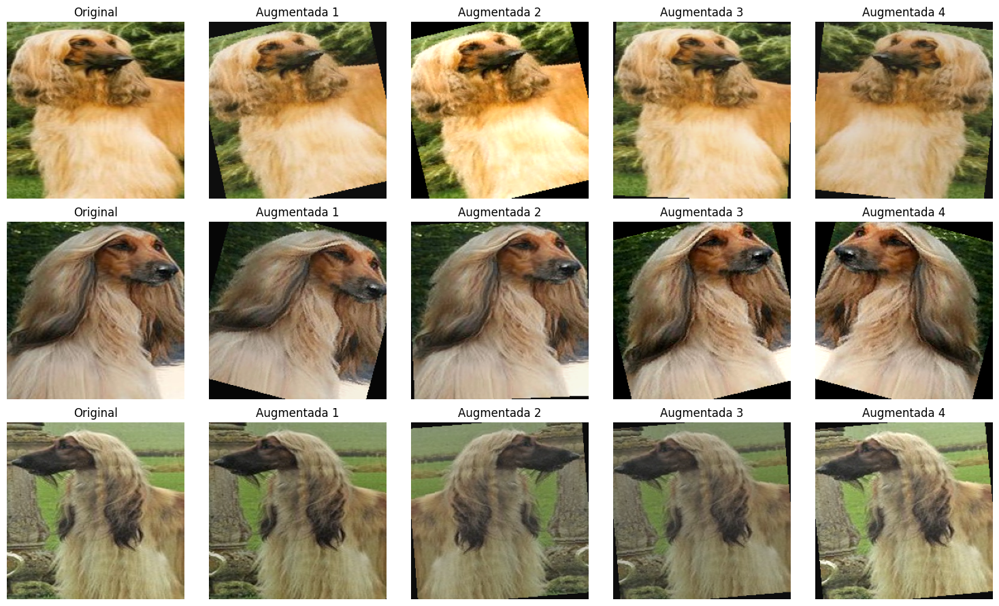

Con el objetivo de incrementar la diversidad efectiva de los datos de entrenamiento y reducir el sobreajuste, se aplicaron técnicas de data augmentation. Estas transformaciones generan variaciones de las imágenes originales mediante modificaciones controladas, permitiendo que el modelo aprenda características más robustas e invariantes. Como resultado, se mejora la capacidad de generalización frente a imágenes nuevas y condiciones de captura diferentes a las observadas durante el entrenamiento.

## 3. Explicación completa del pipeline

El sistema desarrollado está compuesto por tres módulos principales que abordan el problema desde enfoques complementarios: búsqueda por similitud mediante embeddings, clasificación supervisada de razas y detección de perros en imágenes complejas. Cada componente puede utilizarse de forma independiente, pero también se integra dentro de un flujo unificado que permite procesar imágenes, localizar perros y determinar su raza. En las siguientes secciones se describe el funcionamiento de cada etapa y el papel que desempeñan las funciones implementadas dentro del pipeline.

### Embeddings y busqueda por similitud (Etapa 1)

La primera etapa implementa un sistema de recuperación de imágenes basado en similitud visual. El objetivo consiste en representar cada imagen mediante un vector de características (embedding) extraído por una red neuronal preentrenada y utilizar dicha representación para buscar ejemplos visualmente similares dentro de una base vectorial. A partir de los vecinos recuperados, se estima la raza predominante y se determina si la consulta pertenece o no a la distribución conocida mediante un umbral de similitud. Este enfoque aporta interpretabilidad al sistema, ya que las predicciones pueden justificarse mediante ejemplos concretos recuperados de la base de datos.

In [ ]:
Imagen de entrada
        ↓
extract_embedding
        ↓
Embedding de consulta
        ↓
search_similar_images
        ↓
Top-K vecinos más similares
        ↓
predict_breed_from_neighbors
        ↓
Raza predicha o "unknown"

Funciones implementadas: 

**extract_embedding**: Genera una representación vectorial de la imagen utilizando un modelo preentrenado en ImageNet sin su capa de clasificación final. El embedding obtenido captura características visuales de alto nivel y permite comparar imágenes en un espacio de características común.

**search_similar_images**: Utiliza el embedding generado para consultar la base vectorial y recuperar las k imágenes más similares almacenadas. Cada resultado incluye una medida de similitud que indica qué tan cercana es la imagen recuperada respecto de la consulta.


**predict_breed_from_neighbors**: Analiza las razas presentes entre los vecinos recuperados y determina la predicción final mediante un mecanismo de votación. Además, compara la similitud obtenida contra un umbral predefinido; si la similitud máxima es insuficiente, la imagen es considerada fuera de distribución y se devuelve la etiqueta unknown.

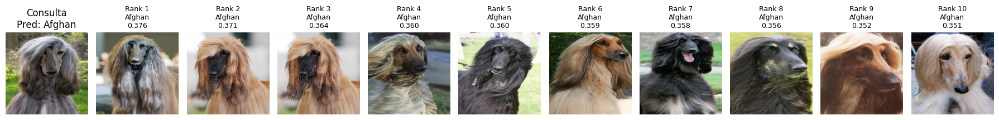

### Clasificación (Etapa 2 - 3)

La segunda etapa corresponde al modelo de clasificación supervisada entrenado sobre el dataset 70-Dogs. A diferencia de la búsqueda por similitud, este enfoque aprende directamente una función que asocia una imagen de entrada con una de las razas disponibles en el conjunto de entrenamiento. El pipeline recibe una imagen completa, realiza el preprocesamiento correspondiente y genera una predicción acompañada de su nivel de confianza. Esta etapa constituye el núcleo del sistema de reconocimiento de razas y proporciona inferencias rápidas una vez finalizado el entrenamiento.

In [ ]:
Imagen de entrada
        ↓
Preprocesamiento
        ↓
classify_image
        ↓
classify_detected_dog
        ↓
Modelo clasificador
        ↓
Raza predicha + confianza
        ↓
Resultado JSON

Funciones implementadas:

**classify_image**: Actúa como punto de entrada para la clasificación de imágenes completas. Esta función reutiliza la lógica implementada para clasificar recortes de perros, tratando la imagen completa como una única detección. Finalmente genera un archivo JSON con la predicción obtenida y la confianza asociada.

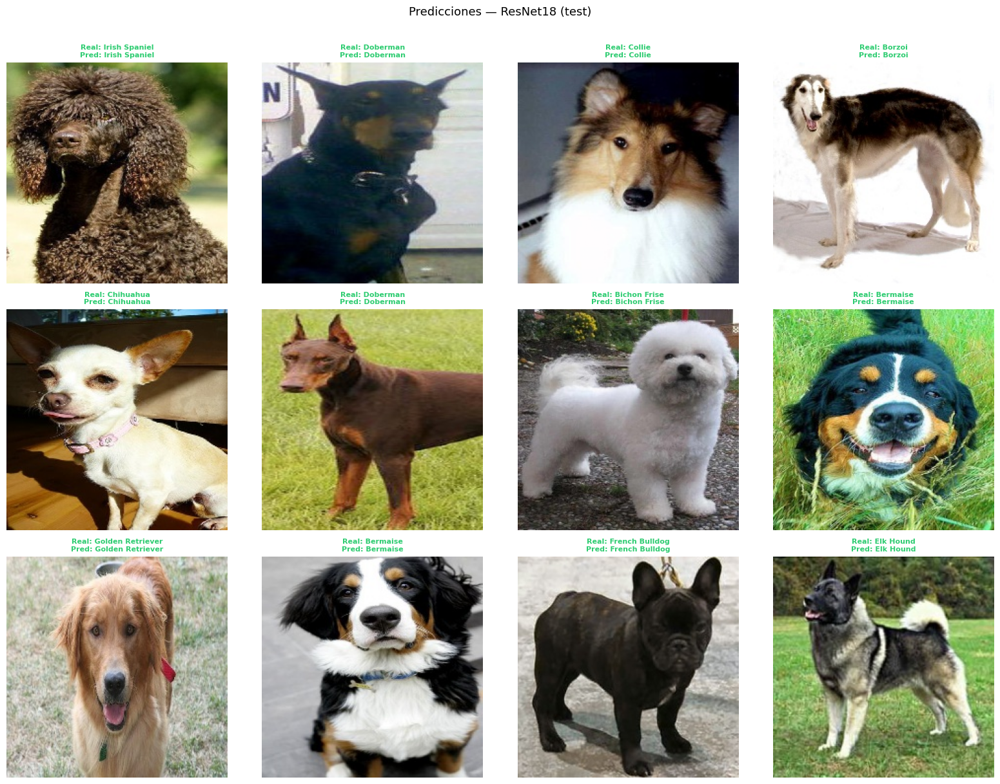

### Detección y Clasificacion (Etapa 2-3)

La tercera etapa extiende el sistema para operar sobre imágenes que pueden contener uno o varios perros. Para ello se incorpora un detector basado en YOLO, encargado de localizar automáticamente cada perro presente en la escena mediante cajas delimitadoras (bounding boxes). Una vez obtenidas las detecciones, cada recorte es procesado individualmente por el clasificador entrenado en la etapa anterior para determinar su raza. Esta combinación permite separar el problema de localización del problema de clasificación, facilitando el procesamiento de escenas más complejas y cercanas a escenarios reales de uso.

In [ ]:
Imagen de entrada
        ↓
detect_dogs (YOLO)
        ↓
Bounding boxes de perros
        ↓
Recorte de cada detección
        ↓
classify_detected_dog
        ↓
Modelo clasificador
        ↓
Raza de cada perro detectado
        ↓
Resultado final

Funciones implementads: 

**detect_dogs**: Utiliza un modelo YOLO preentrenado para localizar automáticamente todos los perros presentes en la imagen. Como resultado genera una colección de bounding boxes que delimitan cada perro detectado junto con sus respectivas puntuaciones de confianza.

**classify_detected_dog**: Recibe el recorte correspondiente a un perro detectado y aplica el clasificador entrenado para estimar su raza. Esta función constituye el nexo entre el detector y el clasificador, permitiendo asignar una etiqueta a cada detección realizada por YOLO.


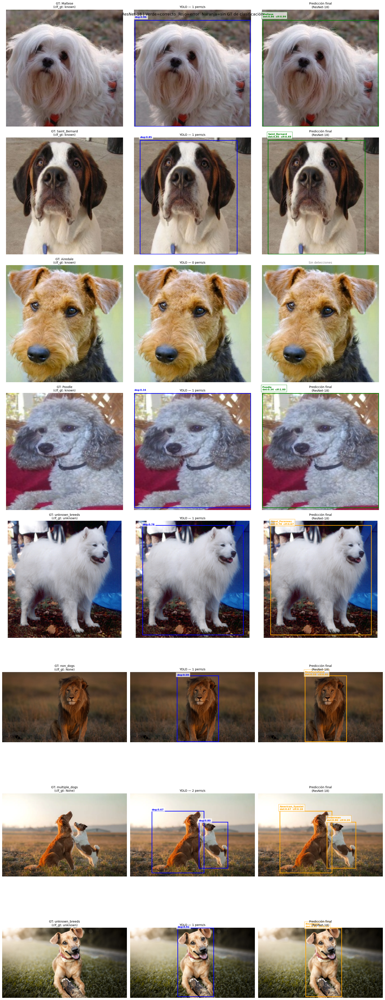

## 4. Justificación de los modelos elegidos

### Etapa 1: Embeddings y busqueda por similitud con ConvNeXt-Tiny

Para la obtener el mejor modelo base evaluamos todas las combinaciones de modelos (`ResNet18`, `ResNet50`, `EfficientNet-B0`, `ConvNeXt-Tiny`) y métricas de similitud (`Coseno`, `Euclidiana`).

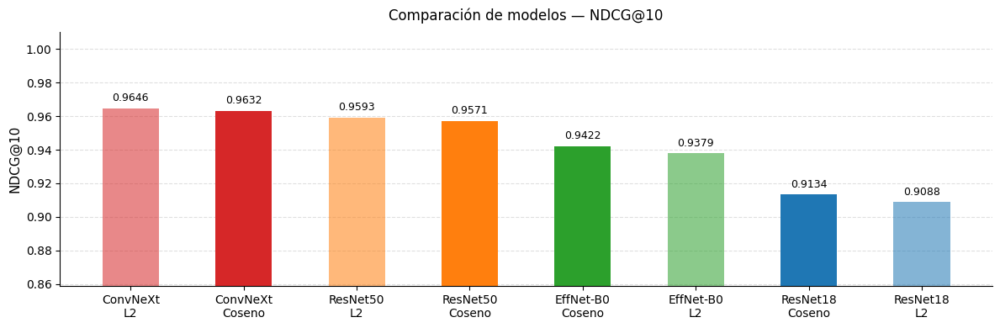

Si bien puede observarse que todos los modelos alcanzan valores elevados de NDCG@10, podemos notar que el modelo ConvNeXt Tiny alcanza el mejor desempeño con ambas métricas, obteniendo un NDCG@10 de 0.9646 con distancia L2 y 0.9632 con distancia Coseno. Muy cerca se ubica ResNet50, cuyos valores (0.9593 y 0.9571) evidencian también una excelente capacidad para generar embeddings discriminativos. En un segundo nivel aparece EfficientNet-B0, mientras que ResNet18 presenta el rendimiento más bajo del conjunto evaluado.

En cuanto a la comparación entre las métricas de distancia, puede observarse que las diferencias son mínimas para todas las arquitecturas (inferiores a 0.005 puntos de NDCG@10). En ConvNeXt Tiny, ResNet50 y ResNet18 la distancia Euclídea obtiene una ligera ventaja, mientras que EfficientNet-B0 presenta un comportamiento marginalmente mejor utilizando similitud por Coseno. Estas diferencias, aunque pequeñas, indican que la elección de la métrica puede depender de la distribución de los embeddings producidos por cada backbone.

En conjunto, los resultados evidencian que la arquitectura utilizada tiene un impacto considerablemente mayor sobre la calidad del ranking que la métrica de similitud empleada. Las diferencias entre modelos alcanzan aproximadamente seis puntos porcentuales de NDCG@10, mientras que el efecto de cambiar entre Coseno y L2 resulta prácticamente no se nota. Esto sugiere que la selección del backbone constituye el principal factor para maximizar el rendimiento del sistema de recuperación.

Por esta razón, se seleccionó ConvNeXt Tiny como el modelo base para las siguientes etapas del trabajo, utilizando la distancia Euclídea (L2) como métrica de similitud. Esta configuración obtuvo el mayor valor de NDCG@10 (0.9646), evidenciando la mejor capacidad para recuperar imágenes relevantes y ordenarlas correctamente según su similitud visual. 

### Etapa 2: Clasificacion con resnet18

#### Comparación de métricas entre modelos

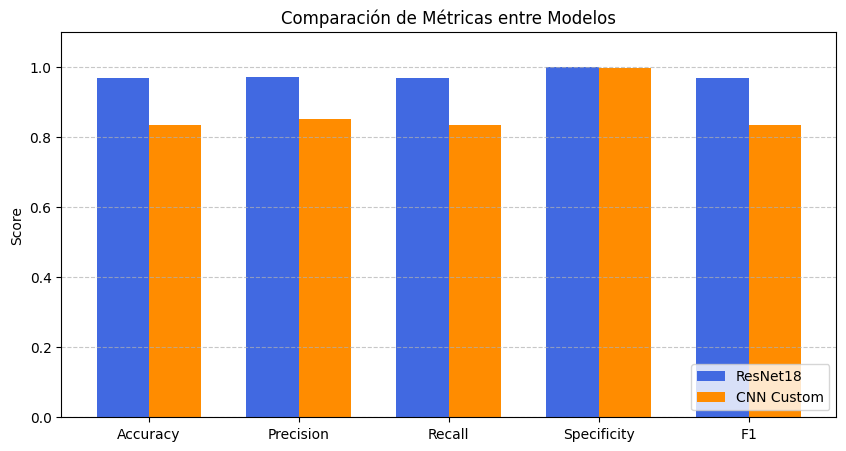

El gráfico permite visualizar de forma inmediata la diferencia de rendimiento entre ambas arquitecturas.

ResNet18 mantiene valores elevados y consistentes en todas las métricas, superando el 96 % en Accuracy, Precision, Recall y F1-score.

Por su parte, la CNN personalizada presenta valores inferiores, aunque consigue superar el 83 % en las principales métricas de clasificación. Esta diferencia evidencia las ventajas de utilizar transferencia de aprendizaje, ya que ResNet18 aprovecha las características visuales adquiridas durante su preentrenamiento en ImageNet.

No obstante, los resultados de la CNN demuestran que también es posible obtener un clasificador con un desempeño considerable sin recurrir a pesos preentrenados, aunque requiere un proceso de entrenamiento considerablemente más prolongado.

#### Comparación de complejidad del modelo

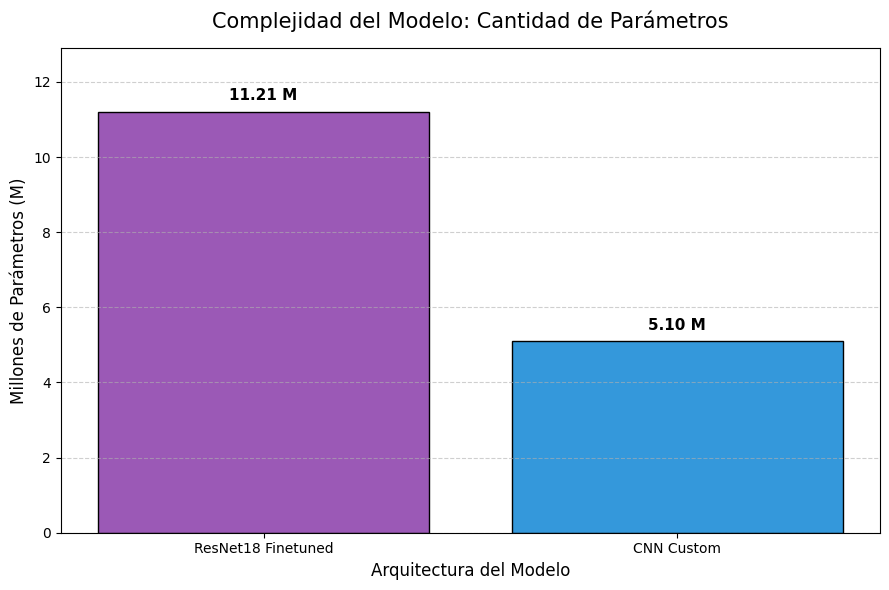

La cantidad de parámetros constituye una medida aproximada de la capacidad de representación de una red neuronal y también se relaciona con el consumo de memoria y el costo computacional del entrenamiento.

En este experimento se observa que ResNet18 Fine-Tuned posee aproximadamente **11.21 millones de parámetros entrenables**, mientras que la arquitectura CNN Custom cuenta con aproximadamente **5.10 millones**.

Esto representa una diferencia considerable en el tamaño de ambas redes. Sin embargo, una mayor cantidad de parámetros no garantiza por sí sola un mejor desempeño, ya que también influyen la arquitectura, la inicialización de los pesos y la estrategia de entrenamiento.

En este caso, ResNet18 consigue mejores resultados a pesar de poseer una mayor cantidad de parámetros. La CNN personalizada, por su parte, presenta una arquitectura más compacta, aunque necesita considerablemente más épocas para alcanzar un desempeño satisfactorio.

Este experimento permite observar el compromiso (*trade-off*) entre complejidad arquitectónica, costo de entrenamiento y capacidad de generalización. Si bien la CNN requiere menos parámetros, ResNet18 ofrece una mejora importante en las métricas de clasificación que justifica su utilización dentro del pipeline propuesto.

### Etapa 3: Detección con YOLOv8n

Para la etapa de detección se seleccionó **YOLOv8n** ya que desde un primer momento nos ofreció un equilibrio adecuado entre precisión, velocidad de inferencia y consumo de recursos computacionales. 

YOLOv8n fue entrenado sobre el dataset COCO, que incluye la clase dog entre sus categorías. Gracias a ello, el modelo posee la capacidad de detectar perros en una amplia variedad de contextos, poses, escalas e iluminaciones sin requerir un proceso adicional de entrenamiento o ajuste fino. Esto permitió incorporar rápidamente un detector confiable dentro del pipeline y concentrar los esfuerzos de entrenamiento en la tarea de clasificación de razas.

Además, su reducido tamaño nos facilitó la ejecución en equipos con recursos limitados, manteniendo tiempos de respuesta adecuados para aplicaciones interactivas. Esta característica resulta especialmente importante en el contexto de la aplicación, donde la experiencia del usuario se beneficia de inferencias rápidas.

En conjunto, la elección de este modelo nos permitió disponer de un detector preciso, eficiente y fácilmente integrable dentro del pipeline completo, proporcionando una solución adecuada para la localización automática de perros en imágenes individuales y escenas con múltiples animales.


## 5. Proceso de entrenamiento e hiperparámetros

El entrenamiento del modelo de clasificación de razas se basa en un esquema de *fine-tuning* sobre arquitecturas preentrenadas en ImageNet, adaptando sus capas finales al número de clases del dataset 70-Dogs. Este enfoque permite aprovechar representaciones visuales ya aprendidas, acelerando la convergencia y mejorando el rendimiento general del modelo en comparación con el entrenamiento desde cero.

Durante el proceso de entrenamiento se utilizaron dos configuraciones principales de modelos: **ResNet18/ResNet50** como arquitecturas basadas en transfer learning, y una **CNN personalizada** diseñada específicamente para el problema. En todos los casos, la última capa completamente conectada fue reemplazada para ajustarse al número de razas a clasificar, incorporando además una capa de dropout para regularización.

#### Hiperparámetros utilizados

Los hiperparámetros del entrenamiento fueron seleccionados para equilibrar capacidad de aprendizaje, estabilidad y generalización del modelo. Se utilizaron **30 épocas** como valor máximo, aunque el entrenamiento no siempre alcanzó este límite debido al uso de *early stopping*, que detiene el proceso cuando no se observan mejoras en la métrica de validación durante **7 épocas consecutivas (patience = 7)**. Este mecanismo permitió evitar el sobreajuste y conservar el estado del modelo con mejor rendimiento.

El **batch size de 32** fue elegido como un compromiso entre eficiencia computacional y estabilidad del gradiente, permitiendo un entrenamiento fluido sin comprometer la capacidad de generalización. En cuanto al **learning rate**, se utilizaron valores diferenciados según la arquitectura: **1e-3 para la CNN personalizada** y **1e-4 para ResNet18/ResNet50**. En el caso de las redes preentrenadas, se empleó un learning rate más bajo para evitar desestabilizar las representaciones aprendidas previamente en ImageNet durante el fine-tuning.

El optimizador seleccionado fue **Adam**, debido a su buena convergencia en problemas de visión y su capacidad de adaptación automática de la tasa de aprendizaje por parámetro. Además, se incorporó un **scheduler ReduceLROnPlateau**, que reduce el learning rate cuando la accuracy en validación deja de mejorar, favoreciendo la convergencia en etapas avanzadas del entrenamiento.

En términos de desempeño, la **CNN personalizada no logró resultados competitivos**, mostrando una menor capacidad de generalización y una convergencia más lenta. En contraste, **ResNet18 obtuvo el mejor rendimiento general**, beneficiándose del preentrenamiento en ImageNet y del proceso de fine-tuning. Este modelo activó el mecanismo de *early stopping*, alcanzando su mejor estado antes de completar el total de épocas previstas y siendo seleccionado como modelo final del sistema.

#### Entrenamiento de ambos modelos

El entrenamiento se realiza utilizando los splits de *train* y *validation*, aplicando previamente las transformaciones definidas en el preprocesamiento. Durante la fase de entrenamiento se incorporan técnicas de data augmentation (flip horizontal, rotaciones y variaciones de color) para mejorar la generalización del modelo.

Además, se aplica una estrategia de **corrección de desbalance de clases**, calculando pesos inversamente proporcionales a la frecuencia de cada clase. Estos pesos se integran en la función de pérdida (*CrossEntropyLoss*) para evitar que el modelo sesgue sus predicciones hacia las clases mayoritarias.

Durante cada época se registran la pérdida de entrenamiento y la *accuracy* en validación, lo que permite construir las curvas de aprendizaje del modelo. El mejor modelo es guardado automáticamente en función de la métrica de validación, y se aplica *early stopping* si no se observan mejoras durante un número determinado de épocas.

En conjunto, este esquema de entrenamiento permite estabilizar el proceso de aprendizaje, reducir el riesgo de sobreajuste y obtener modelos capaces de generalizar sobre imágenes no vistas durante el entrenamiento. A continuación vemos gráficos de pérdida y accuracy en el entrenamiento de los modelos.

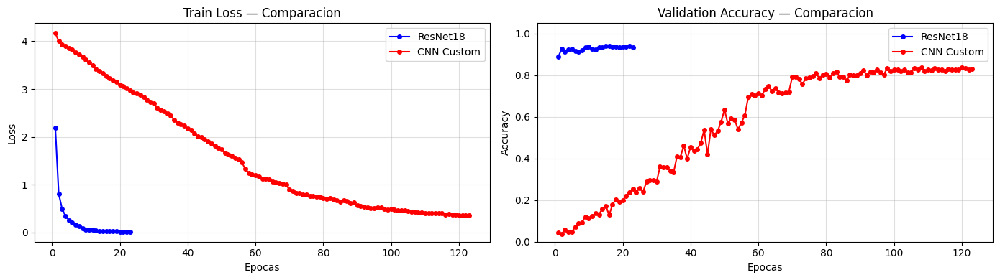

Las curvas de entrenamiento muestran comportamientos claramente diferentes entre ambas arquitecturas.

ResNet18 alcanza rápidamente una elevada precisión de validación y una reducción significativa de la pérdida de entrenamiento. Posteriormente, ambas métricas tienden a estabilizarse, indicando que el proceso de *fine-tuning* aprovecha eficazmente las representaciones aprendidas durante el preentrenamiento.

Por el contrario, la CNN personalizada presenta un aprendizaje considerablemente más gradual. Durante las primeras épocas su precisión de validación es baja, pero aumenta progresivamente hasta alcanzar valores cercanos al 83 %. Simultáneamente, la pérdida de entrenamiento disminuye de manera sostenida, evidenciando que la red continúa ajustando sus parámetros para mejorar la clasificación.

La diferencia en la duración de ambos entrenamientos también resulta significativa: ResNet18 finalizó luego de 23 épocas, mientras que la CNN personalizada necesitó 123 épocas antes de activar el mecanismo de *Early Stopping*.

Este comportamiento es esperable debido a que ResNet18 parte de pesos preentrenados sobre ImageNet, mientras que la CNN debe aprender todas las representaciones visuales desde cero.

Finalmente, aunque la CNN requiere un proceso de optimización considerablemente más prolongado, logra alcanzar un desempeño satisfactorio. Sin embargo, ResNet18 mantiene una ventaja importante tanto en velocidad de convergencia como en precisión de validación.

## 6. Resultados obtenidos

### Etapa 1: Embeddings y busqueda por similitud

#### Visualización de los embeddings mediante t-SNE

Con el objetivo de analizar cualitativamente la calidad de las representaciones aprendidas por el modelo seleccionado, se proyectaron los embeddings de alta dimensión sobre un espacio bidimensional mediante **t-distributed Stochastic Neighbor Embedding (t-SNE)**. Esta técnica de reducción de dimensionalidad preserva, en la medida de lo posible, las relaciones de vecindad entre muestras, permitiendo visualizar cómo se agrupan las imágenes según las características extraídas por el backbone.


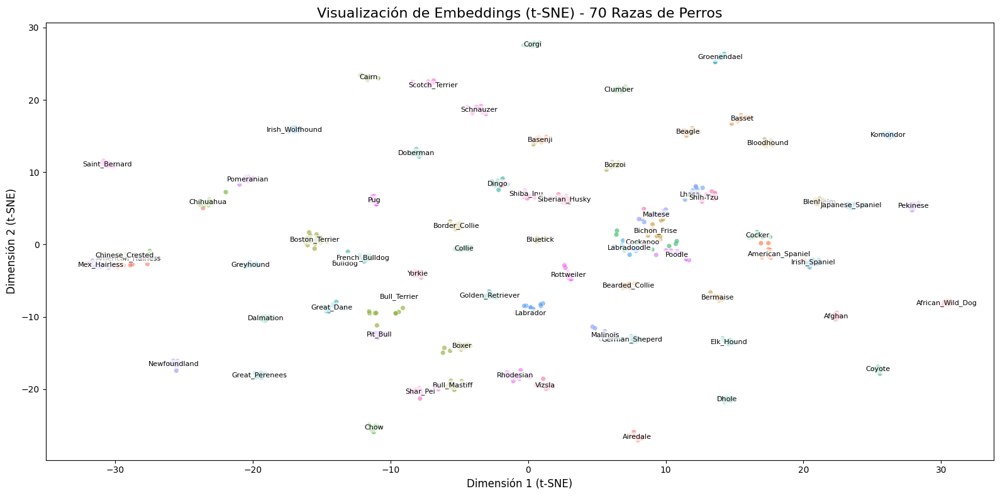

La proyección obtenida evidencia que los embeddings generados por **ConvNeXt Tiny** presentan una estructura discriminativa consistente. En la mayoría de las razas, las imágenes correspondientes se agrupan formando clústeres compactos, indicando que el modelo logra extraer representaciones similares para ejemplares de una misma categoría.

Asimismo, puede observarse que razas con características morfológicas similares tienden a ubicarse relativamente próximas entre sí, mientras que aquellas con rasgos visuales claramente diferenciados aparecen separadas en el espacio proyectado. Esta organización constituye un indicio de que el espacio de embeddings preserva adecuadamente las relaciones semánticas necesarias para realizar búsquedas por similitud.

Si bien existen algunos grupos parcialmente solapados —un comportamiento esperable debido a las similitudes visuales entre determinadas razas y a la reducción de dimensionalidad realizada por t-SNE—, la separación global observada resulta consistente con el elevado desempeño obtenido posteriormente en las métricas de recuperación.


#### Métricas finales

Finalmente, una vez fijados el backbone, la métrica de similitud, el umbral de aceptación y el número de vecinos, se evaluó el sistema completo sobre el conjunto **Test**, el cual permaneció completamente aislado durante todas las etapas de selección y optimización de hiperparámetros.


In [ ]:
========================================
   Evaluación final — Test
========================================
   Accuracy global:          0.2629
   Accuracy sobre aceptadas: 0.9787
   NDCG@10:                  0.9774
   Cobertura:                0.2686
   Aceptadas:                188
   Rechazadas:               512
========================================

Los resultados muestran una **Accuracy sobre consultas aceptadas del 97.87%**, indicando que, cuando el sistema considera que una consulta pertenece a la distribución conocida, la predicción de la raza resulta altamente confiable. Este comportamiento se complementa con un **NDCG@10 de 0.9774**, valor que confirma que las imágenes relevantes aparecen correctamente posicionadas entre los primeros resultados del ranking de recuperación.

Por otra parte, la **cobertura del 26.86%** indica que únicamente una fracción de las consultas supera el umbral de aceptación establecido. En consecuencia, la **Accuracy global** se reduce al 26.29%, ya que las consultas rechazadas se contabilizan como predicciones incorrectas. Este resultado no constituye una limitación del modelo de embeddings, sino una consecuencia directa de haber priorizado un criterio de aceptación conservador durante la optimización del *threshold*.

En conjunto, estas métricas reflejan el compromiso asumido entre cobertura y confiabilidad. El modelo realiza predicciones únicamente cuando existe suficiente evidencia de similitud, minimizando así el riesgo de asignar una raza incorrecta a imágenes ambiguas o fuera de distribución. 


### Etapa 2: Clasificacion

#### Métricas finales

Finalizado el entrenamiento, el mejor modelo almacenado durante la validación se evalúa utilizando exclusivamente el conjunto de prueba.

In [ ]:
========================================
  Evaluación final — Test
========================================
  accuracy       : 0.9700
  precision      : 0.9716
  recall         : 0.9700
  specificity    : 0.9996
  f1             : 0.9695

Los resultados obtenidos muestran un desempeño elevado en todas las métricas evaluadas.

La **accuracy** indica que aproximadamente el **97 %** de las imágenes del conjunto de prueba fueron clasificadas correctamente. Asimismo, los valores de **precision**, **recall** y **F1-score** presentan resultados consistentes entre sí, lo que sugiere un comportamiento equilibrado del clasificador y ausencia de sesgos importantes hacia determinadas clases.

Por otra parte, la **specificity** cercana a 1 evidencia una baja tasa de falsos positivos cuando se considera cada raza mediante un enfoque *one-vs-rest*, indicando una buena capacidad para distinguir correctamente entre clases diferentes.

#### Matriz de confusión

Las métricas globales resumen el desempeño general del modelo, pero no permiten identificar cuáles son las razas que presentan mayores dificultades de clasificación.

Para ello se analiza la matriz de confusión, representando únicamente los errores cometidos por el modelo.

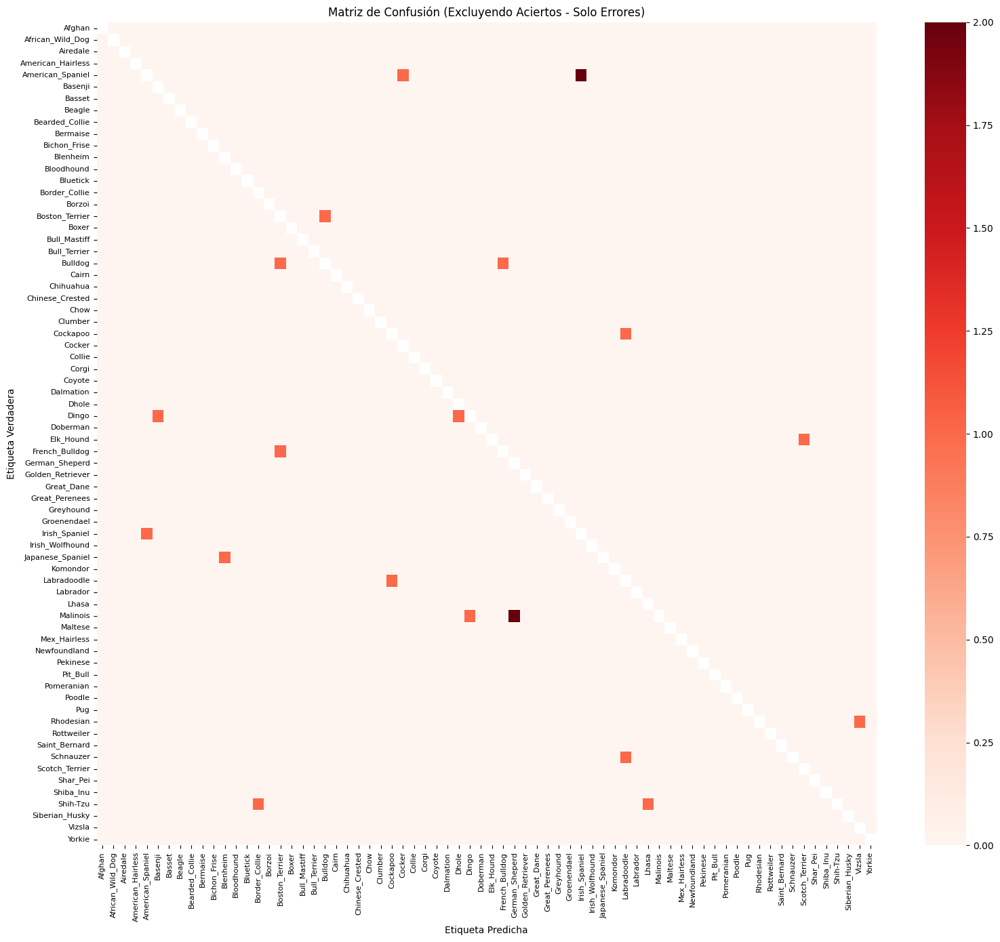

In [ ]:
--- Top 5 Peores Confusiones ---
El modelo confundió 2 veces un 'American_Spaniel' con un 'Irish_Spaniel'
El modelo confundió 2 veces un 'Malinois' con un 'German_Sheperd'
El modelo confundió 1 veces un 'American_Spaniel' con un 'Cocker'
El modelo confundió 1 veces un 'Boston_Terrier' con un 'Bulldog'
El modelo confundió 1 veces un 'Bulldog' con un 'Boston_Terrier'

La matriz de confusión permite identificar las parejas de razas que el modelo confunde con mayor frecuencia.

En este experimento, las principales confusiones corresponden a:

- American Spaniel ↔ Irish Spaniel
- Malinois ↔ German Sheperd
- American Spaniel ↔ Cocker
- Boston Terrier ↔ Bulldog

Estas confusiones resultan razonables desde el punto de vista visual, ya que corresponden a razas pertenecientes a grupos similares o que comparten características morfológicas como la forma del hocico, la longitud del pelaje o la estructura corporal.

Este análisis permite detectar posibles limitaciones del conjunto de entrenamiento y constituye una herramienta útil para orientar mejoras futuras, como incorporar un mayor número de imágenes representativas de las clases problemáticas o aplicar técnicas de aumento de datos más específicas para dichas razas.

### Etapa 3: Detección y Clasificacion

A diferencia de las métricas mostradas anteriormente para los clasificadores aislados, estos resultados incorporan simultáneamente los errores producidos por la etapa de detección y por la etapa de clasificación.

In [ ]:
| Métrica           |   ResNet-18 |   CNN Custom |     ResNet-18 |    CNN Custom |
|                   |      (Test) |       (Test) |   (OOD known) |   (OOD known) |
|-------------------|-------------|--------------|---------------|---------------|
| Accuracy          |      0.58   |       0.4771 |        0.6875 |        0.5    |
| Precision (macro) |      0.9405 |       0.773  |        0.4545 |        0.4167 |
| Recall (macro)    |      0.5718 |       0.4704 |        0.4273 |        0.3667 |
| F1-score (macro)  |      0.6755 |       0.5566 |        0.4385 |        0.381  |

Los resultados muestran una diferencia importante entre las métricas obtenidas por los clasificadores aislados y las observadas en el pipeline completo.

El dato más relevante es la cantidad de imágenes donde YOLO no logra detectar ningún perro:

Test: 279 imágenes sin detección (39.9%).

OOD known_breeds: 2 imágenes sin detección (12.5%).

Esta diferencia resulta especialmente significativa porque el conjunto Test contiene imágenes ya recortadas y centradas sobre el perro, mientras que las imágenes OOD conservan el contexto natural presente en escenas reales.

Los resultados respaldan la hipótesis planteada inicialmente: YOLO fue preentrenado sobre COCO utilizando escenas naturales y, en consecuencia, presenta mayores dificultades cuando recibe imágenes excesivamente recortadas, como ocurre con una parte importante del conjunto Test. No obstante, debido al tamaño reducido del conjunto OOD (16 imágenes), esta tendencia debe interpretarse con cierta cautela.

Esto explica por qué ResNet-18 pasa de una accuracy del 97% cuando se evalúa de forma aislada a aproximadamente 58% cuando forma parte del pipeline completo. Una parte importante de esa degradación está relacionada con los fallos de detección introducidos por YOLO, que impiden que el clasificador procese numerosas imágenes.

Por otra parte, la diferencia entre ResNet-18 y CNN Custom continúa siendo evidente en ambos conjuntos. En Test, ResNet-18 alcanza un F1-score de 0.6755 frente a 0.5566 de CNN Custom, mientras que en OOD obtiene 0.4385 frente a 0.3810. Esto confirma la ventaja de las representaciones aprendidas mediante transferencia de aprendizaje, incluso cuando ambos modelos se integran dentro del mismo pipeline.

## 7. Comparación entre enfoques


En esta sección se realiza una comparación entre los distintos enfoques utilizados en el sistema, analizando sus ventajas, limitaciones y comportamiento general. En particular, se contrastan dos aspectos principales: la **búsqueda por similitud vs clasificación supervisada**, y el desempeño de los modelos de clasificación utilizados (**ResNet18 fine-tuned vs CNN personalizada**).



### Búsqueda por similitud vs clasificación supervisada

El enfoque basado en **búsqueda por similitud** permite recuperar ejemplos visualmente cercanos a partir de una base de embeddings, lo que aporta una ventaja importante en términos de interpretabilidad, ya que las predicciones pueden justificarse mediante imágenes concretas del dataset. Además, este método facilita la detección de casos fuera de distribución mediante el uso de un umbral de similitud. Sin embargo, su rendimiento depende fuertemente de la calidad de la base vectorial y puede ser más sensible a variaciones visuales.

Por otro lado, la **clasificación supervisada** mediante redes neuronales aprende directamente una función de mapeo entre imágenes y clases, lo que generalmente se traduce en predicciones más rápidas y precisas una vez entrenado el modelo. A diferencia del enfoque por similitud, no requiere consultar una base externa en tiempo de inferencia, aunque pierde interpretabilidad directa en sus decisiones.

En conjunto, ambos enfoques resultan complementarios: la búsqueda por similitud aporta explicabilidad y capacidad de rechazo (unknown), mientras que la clasificación supervisada ofrece mayor eficiencia y robustez en la predicción directa de razas.

### ResNet18 fine-tuned vs CNN personalizada

En cuanto a los modelos de clasificación, se observó una diferencia significativa entre la CNN personalizada y la ResNet18 preentrenada con fine-tuning. La CNN propia mostró limitaciones en su capacidad de generalización, presentando una convergencia más lenta y resultados inferiores, posiblemente debido a la menor profundidad del modelo y a las restricciones computacionales que limitaron su entrenamiento.

En contraste, ResNet18 obtuvo el mejor desempeño global, beneficiándose del preentrenamiento en ImageNet, lo que le permite partir de representaciones visuales ya aprendidas. Este modelo no solo alcanzó mejores métricas de validación, sino que también obtuvo una accuracy del 97% sobre el conjunto Test en la evaluación aislada del clasificador, consolidándose como la arquitectura final seleccionada para el sistema.

Sin embargo, al integrar ambos clasificadores dentro del pipeline con YOLO, se observa que el rendimiento global disminuye debido a los errores introducidos por la etapa de detección. Aun así, ResNet18 mantiene una ventaja significativa frente a CNN Custom en los dos conjuntos evaluados.

En conclusión, los resultados evidencian la superioridad de los modelos preentrenados frente a arquitecturas diseñadas desde cero en este contexto, especialmente cuando se dispone de recursos limitados y un dataset de tamaño moderado.

## 8. Problemas encontrados y soluciones implementadas

Durante el desarrollo del proyecto se identificaron diversas limitaciones tanto en el entrenamiento de los modelos como en la integración de los distintos componentes del pipeline. Estas dificultades no solo afectaron el rendimiento final, sino que también permitieron establecer posibles líneas de mejora para trabajos futuros.

En primer lugar, el entrenamiento de la **CNN personalizada** no logró alcanzar una convergencia satisfactoria dentro de las restricciones de tiempo y capacidad de cómputo disponibles. Aunque el modelo mostró cierto aprendizaje inicial, su rendimiento fue considerablemente inferior al obtenido con arquitecturas preentrenadas. Esto sugiere que, con un mayor número de épocas, un ajuste más fino de hiperparámetros o mayor capacidad de cómputo, la CNN podría haber alcanzado mejores resultados. Sin embargo, en el contexto del proyecto, se priorizó el uso de modelos más robustos como ResNet18.

En segundo lugar, se observó que el modelo de detección **YOLOv8n**, al estar preentrenado sobre el dataset general COCO, no está específicamente optimizado para el dominio del problema. Si bien es capaz de detectar la clase *dog* sin necesidad de reentrenamiento, su rendimiento presenta diferencias importantes según las características de las imágenes de entrada. En particular, se observó una mayor cantidad de fallos sobre el conjunto Test, cuyas imágenes están previamente recortadas y centradas sobre el perro. Por el contrario, sobre las imágenes OOD, que conservan el contexto natural de la escena, se obtuvo una menor proporción de imágenes sin detección. Esta diferencia sugiere que las características de las imágenes de entrada influyen considerablemente en el comportamiento del detector.

Finalmente, se identificó una posible mejora estructural en el pipeline completo de detección y clasificación. Actualmente, el clasificador es entrenado sobre imágenes originales del dataset, mientras que en el sistema final recibe recortes generados por YOLO. Esta discrepancia introduce una diferencia entre el dominio de entrenamiento y el dominio de inferencia, lo que puede afectar el rendimiento global del sistema. Una mejora potencial consistiría en entrenar el clasificador directamente sobre recortes generados por YOLO, lo que permitiría una mayor coherencia entre ambas etapas. Sin embargo, esta solución no fue implementada debido a la necesidad de un dataset significativamente más grande y etiquetado bajo este nuevo esquema, lo cual excedía el alcance del proyecto.